# Objective Functions for Marketers: How Models Decide What "Best" Means

**Companion notebook for the Marketing Data Science article**
by Joe Domaleski, [Country Fried Creative](https://countryfriedcreative.com) | [blog.marketingdatascience.ai](https://blog.marketingdatascience.ai)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joedom99/objective-functions-for-marketers/blob/main/objective_functions_for_marketers.ipynb)

---

## What this notebook does

Every optimization problem, from an ad platform's bidding algorithm to a media mix model to a marketing budget meeting, is trying to make some number as large or as small as possible. That number is the **objective function**. It's how a model decides what "best" means.

Most of the time, nobody writes it down. A platform default gets used, or a team optimizes whatever metric shows up on the dashboard. But the objective decides the answer. Change it, and the same channels, the same budget, and the same optimizer produce a different "best" plan.

This notebook works through one marketing budget problem in four steps:

1. **Same channels, different objectives.** The optimal budget changes depending on whether you maximize conversions, revenue, or profit.
2. **Constraints change the answer, and they cost something.** CPA targets, ROAS targets, and channel commitments each move the profit-maximizing plan and give up some profit.
3. **Blending goals into a utility function.** When you care about more than one outcome, the weights you choose are the business decision.
4. **Which objective fits your business?** A practical guide to matching the objective to the situation, plus what can go wrong even with the right one.

It ends with a brief note on loss functions, the objectives that models minimize when they learn from data. That's a topic for a future article.

## What's inside

1. Setup
2. The anatomy of an optimization problem
3. Part 1: Same channels, different objectives
4. Part 2: Constraints change the answer
5. Part 3: Blending goals into a utility function
6. Part 4: Which objective fits your business?
7. A brief note on loss functions
8. Checking the results
9. Summary

Everything here is simulated with illustrative assumptions, not client data. A fixed random seed keeps the results reproducible. They should match mine closely, though tiny differences in the last digit can appear across library versions.

The settings live in a few clearly labeled cells: `P` for the channels and budget, `R` for the business rules, and `U` for the utility sweep. The numbers quoted in the text describe the default settings. If you change a setting, the code, charts, and tables update, but the written explanations won't.

## 1. Setup

This notebook only uses libraries that come preinstalled in Google Colab: NumPy, pandas, Matplotlib, and SciPy. The figures and table images are saved to `figures/` and `tables/` at 300 dpi. Each table is also saved as a CSV file.

In [1]:
import os
import textwrap
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch
from scipy.optimize import minimize, minimize_scalar

SEED = 42
rng = np.random.default_rng(SEED)

os.makedirs("figures", exist_ok=True)
os.makedirs("tables", exist_ok=True)
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.4.6 | pandas 2.2.3


### Figure and table style

Figures use my company's Country Fried Creative color palette on a white background. The cell below tries to download the Lato font. If that fails, Matplotlib falls back to its default font and everything still works.

The `render_table` helper turns a small table into an image you can drop straight into an article.

In [2]:
# Country Fried Creative brand palette
TEAL   = "#6db7ac"
ORANGE = "#f58235"
RED    = "#c02126"
NAVY   = "#212f3f"
GREEN  = "#198a53"
GOLD   = "#eec35b"
GRAY   = "#8a929b"
CARD   = "#f2f3f5"
ACCENTS = [TEAL, ORANGE, GOLD, RED, NAVY, GREEN]

def load_lato():
    base = "https://raw.githubusercontent.com/google/fonts/main/ofl/lato/"
    try:
        for style in ["Lato-Regular.ttf", "Lato-Bold.ttf"]:
            path = os.path.join("/tmp", style)
            if not os.path.exists(path):
                urllib.request.urlretrieve(base + style, path)
            font_manager.fontManager.addfont(path)
        return True
    except Exception as e:
        print("Could not load Lato, using the default font instead:", e)
        return False

HAS_LATO = load_lato()

plt.rcParams.update({
    "font.family": "Lato" if HAS_LATO else "DejaVu Sans",
    "font.size": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": NAVY,
    "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e8eb",
    "grid.linewidth": 0.8,
    "xtick.color": NAVY,
    "ytick.color": NAVY,
    "legend.frameon": False,
    "text.parse_math": False,  # treat $ signs as plain text
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

def save(fig, name):
    path = os.path.join("figures", name)
    fig.savefig(path)
    print("Saved", path)

def dollars(x, pos=None):
    return f"${x:,.0f}"

def dollars_k(x, pos=None):
    return "$0" if x == 0 else f"${x/1000:,.0f}k"

def render_table(fname, title, subtitle, df, widths, fs=11.5):
    # Draw a DataFrame as a styled table image and save it to tables/.
    headers = list(df.columns)
    rows = df.astype(str).values.tolist()
    cw, lh = 0.0074 * fs, 0.0225 * fs
    px, py, gap, accent_w = 0.16, 0.14, 0.10, 0.09
    col_w = [w * cw + 2 * px for w in widths]
    W = sum(col_w) + accent_w
    wrap = lambda t, w: textwrap.wrap(str(t), w, break_on_hyphens=False) or [""]
    hl = [wrap(h, w) for h, w in zip(headers, widths)]
    bl = [[wrap(c, w) for c, w in zip(r, widths)] for r in rows]
    hh = max(map(len, hl)) * lh + 2 * py
    rh = [max(map(len, r)) * lh + 2 * py for r in bl]
    top = 1.15
    H = top + hh + gap + sum(rh) + gap * len(rows) + 0.1

    fig = plt.figure(figsize=(W + 0.4, H))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(-0.2, W + 0.2); ax.set_ylim(H, 0); ax.axis("off")
    ax.text(W / 2, 0.38, title, fontsize=fs + 13, fontweight="bold", color=NAVY, ha="center", va="center")
    ax.text(W / 2, 0.86, subtitle, fontsize=fs + 2.5, color=GRAY, ha="center", va="center")

    y = top
    ax.add_patch(FancyBboxPatch((0, y), W, hh, boxstyle="round,pad=0,rounding_size=0.14", fc=NAVY, ec="none"))
    x = accent_w
    for lines, w in zip(hl, col_w):
        ax.text(x + px, y + hh / 2, "\n".join(lines), color="white", fontsize=fs + 1,
                fontweight="bold", va="center", linespacing=1.2)
        x += w
    y += hh + gap
    for i, (r, h) in enumerate(zip(bl, rh)):
        ax.add_patch(FancyBboxPatch((0, y), W, h, boxstyle="round,pad=0,rounding_size=0.14", fc=CARD, ec="none"))
        ax.add_patch(FancyBboxPatch((0, y), accent_w + 0.06, h, boxstyle="round,pad=0,rounding_size=0.06",
                                    fc=ACCENTS[i % len(ACCENTS)], ec="none"))
        ax.add_patch(plt.Rectangle((accent_w, y), 0.06, h, fc=CARD, ec="none"))
        x = accent_w
        for j, (lines, w) in enumerate(zip(r, col_w)):
            ax.text(x + px, y + py, "\n".join(lines), color=NAVY, fontsize=fs,
                    fontweight="bold" if j == 0 else "normal", va="top", linespacing=1.3)
            x += w
        y += h + gap
    path = os.path.join("tables", fname)
    fig.savefig(path, dpi=300, facecolor="white", bbox_inches=None)
    plt.close(fig)
    df.to_csv(path.replace(".png", ".csv"), index=False)  # selectable text version
    print("Saved", path, "and a CSV copy")

print("Font:", plt.rcParams["font.family"])

Font: ['Lato']


## 2. The anatomy of an optimization problem

Every optimization problem has three parts, whether a computer solves it or a marketing team argues it out in a meeting:

- **Decision variables** are what you can change, such as how much to spend in each channel.
- **The objective function** is what "best" means, written as a number to maximize or minimize, such as profit.
- **Constraints** are the rules the answer has to follow, such as staying within budget or keeping CPA under a target.

When a business cares about more than one outcome, it needs a way to combine them into a single objective. That's where **utility** comes in. Economists use the word for the overall value a decision produces, and a utility function is one way to define the objective when there are competing goals. Not every objective is a utility function, though. A model fitting data, for example, minimizes its errors, which we'll come back to at the end.

A quick definition before we start. In this notebook, **profit** means contribution profit after advertising: revenue times gross margin, minus ad spend. It doesn't subtract other operating costs like salaries or rent, so it's not the same as accounting net profit. It's the right number for comparing marketing plans, because it captures what the marketing itself earns.

The response curves below are assumptions, not estimates from real campaign data. In practice, they'd come from a media mix model or experiments, and any optimization is only as reliable as those curves.

Here's a simple example with one channel. As spend rises, revenue keeps climbing, but more slowly. Profit rises and then falls. "Maximize revenue" and "maximize profit" point to very different spending levels on the same curve.

Saved figures/fig01_one_channel_two_objectives.png


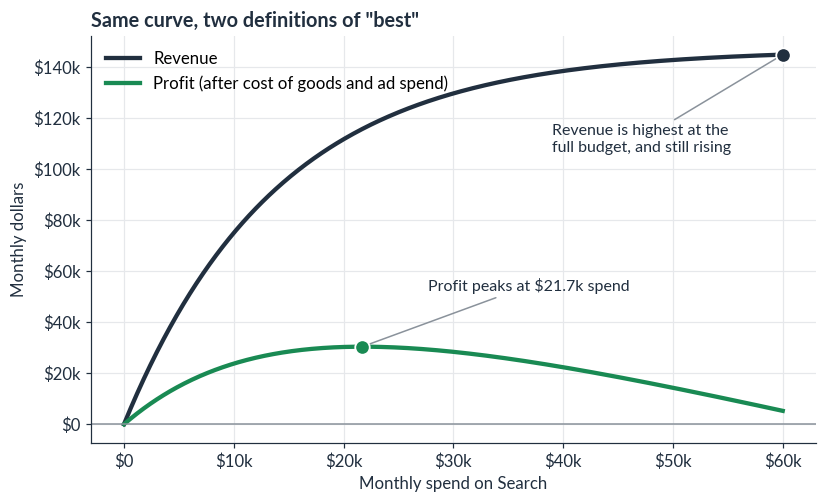

Saved tables/table01_objective_anatomy.png and a CSV copy


,Part,The question it answers,Budget example
0,Decision variables,What can we change?,"Monthly spend in Search, Social, and Display"
1,Objective function,"What does ""best"" mean?",Maximize profit
2,Constraints,What rules must the answer follow?,"Total spend of $60,000 or less; CPA of $20 or ..."
3,Utility (for multiple goals),How much do we value each outcome?,"Objective = 70% weight on profit, 30% on conve..."


In [3]:
P = {
    "budget": 60000,                      # most we can spend in a month
    "channels": ["Search", "Social", "Display"],
    "max_conversions": [700, 1400, 650],  # most conversions each channel can produce in a month
    "saturation_scale": [14000, 6000, 11000],  # spend at which a channel reaches about 63% of its maximum
    "value_per_conversion": [210, 55, 120],    # average revenue per conversion
    "gross_margin": 0.45,                 # share of revenue left after cost of goods
}

CH = P["channels"]
Cmax = np.array(P["max_conversions"], dtype=float)
Ksat = np.array(P["saturation_scale"], dtype=float)
VAL = np.array(P["value_per_conversion"], dtype=float)
BUDGET = P["budget"]

def conversions(s):
    # Diminishing returns: each extra dollar buys a little less than the one before
    return Cmax * (1 - np.exp(-np.asarray(s, dtype=float) / Ksat))

def outcomes(s, margin=None):
    margin = P["gross_margin"] if margin is None else margin
    s = np.asarray(s, dtype=float)
    conv = conversions(s)
    rev = (conv * VAL).sum()
    spend = s.sum()
    return {"Spend": spend, "Conversions": conv.sum(), "Revenue": rev,
            "Profit": margin * rev - spend,
            "CPA": spend / conv.sum() if conv.sum() > 0 else np.nan,
            "ROAS": rev / spend if spend > 0 else np.nan}

# One channel on its own: Search
grid = np.linspace(0, BUDGET, 601)
rev1 = Cmax[0] * (1 - np.exp(-grid / Ksat[0])) * VAL[0]
prof1 = P["gross_margin"] * rev1 - grid
best_i = prof1.argmax()

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(grid, rev1, color=NAVY, lw=2.8, label="Revenue")
ax.plot(grid, prof1, color=GREEN, lw=2.8, label="Profit (after cost of goods and ad spend)")
ax.scatter([grid[best_i]], [prof1[best_i]], s=90, color=GREEN, edgecolor="white", linewidth=1.2, zorder=4)
ax.annotate(f"Profit peaks at ${grid[best_i]/1000:,.1f}k spend", xy=(grid[best_i], prof1[best_i]),
            xytext=(grid[best_i] + 6000, prof1[best_i] + 22000), color=NAVY, fontsize=10.5,
            arrowprops=dict(arrowstyle="-", color=GRAY))
ax.scatter([grid[-1]], [rev1[-1]], s=90, color=NAVY, edgecolor="white", linewidth=1.2, zorder=4)
ax.annotate("Revenue is highest at the\nfull budget, and still rising", xy=(grid[-1], rev1[-1]),
            xytext=(grid[-1] - 21000, rev1[-1] - 38000), color=NAVY, fontsize=10.5,
            arrowprops=dict(arrowstyle="-", color=GRAY))
ax.axhline(0, color=GRAY, lw=1)
ax.set_xlabel("Monthly spend on Search")
ax.set_ylabel("Monthly dollars")
ax.xaxis.set_major_formatter(dollars_k)
ax.yaxis.set_major_formatter(dollars_k)
ax.set_title("Same curve, two definitions of \"best\"")
ax.legend(loc="upper left")
save(fig, "fig01_one_channel_two_objectives.png")
plt.show()

anatomy = pd.DataFrame({
    "Part": ["Decision variables", "Objective function", "Constraints", "Utility (for multiple goals)"],
    "The question it answers": ["What can we change?", "What does \"best\" mean?",
                                "What rules must the answer follow?", "How much do we value each outcome?"],
    "Budget example": ["Monthly spend in Search, Social, and Display", "Maximize profit",
                       "Total spend of $60,000 or less; CPA of $20 or less",
                       "Objective = 70% weight on profit, 30% on conversions"],
})
render_table("table01_objective_anatomy.png", "The anatomy of an optimization problem",
             "Three parts, plus utility when there's more than one goal", anatomy, [22, 30, 40])
anatomy

On its own, Search is most profitable at about $21,700 a month. Past that point, each extra ad dollar brings back less than a dollar in contribution (revenue times margin), so profit falls even though revenue keeps going up. If the objective is revenue, the optimizer spends everything. If the objective is profit, it stops. Same curve, same data, different answer.

The key idea is the **marginal return**, what the next dollar brings back. A profit objective keeps spending as long as the next dollar brings back more than a dollar in contribution. At the optimum, the next dollar brings back exactly a dollar, so it adds nothing to profit. A revenue or conversion objective keeps spending as long as the next dollar brings back anything at all.

## 3. Part 1: Same channels, different objectives

Now add two more channels. Each has diminishing returns, and each differs in what a conversion is worth:

- **Search** converts at a moderate cost, but its customers are valuable.
- **Social** produces cheap conversions with lower value.
- **Display** sits in the middle.

Saved figures/fig02_channel_response_curves.png


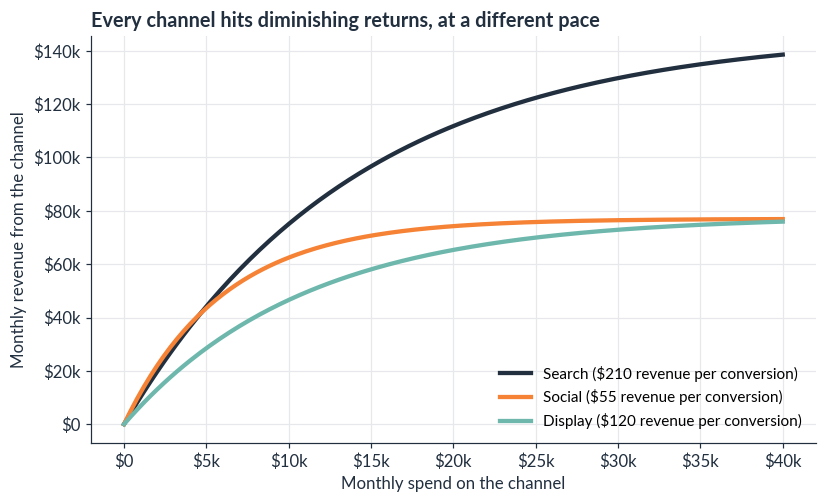

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
g = np.linspace(0, 40000, 200)
for i, (c, col) in enumerate(zip(CH, [NAVY, ORANGE, TEAL])):
    s = np.zeros((len(g), 3)); s[:, i] = g
    ax.plot(g, conversions(s)[:, i] * VAL[i], color=col, lw=2.8, label=f"{c} (${VAL[i]:.0f} revenue per conversion)")
ax.set_xlabel("Monthly spend on the channel")
ax.set_ylabel("Monthly revenue from the channel")
ax.xaxis.set_major_formatter(dollars_k)
ax.yaxis.set_major_formatter(dollars_k)
ax.set_title("Every channel hits diminishing returns, at a different pace")
ax.legend(loc="lower right", fontsize=10)
save(fig, "fig02_channel_response_curves.png")
plt.show()

We'll give the same optimizer three different objectives and let it split up to $60,000 across the channels:

1. **Max conversions:** as many conversions as possible.
2. **Max revenue:** as much revenue as possible.
3. **Max profit:** as much contribution profit as possible. The optimizer is free to leave budget unspent.

Only the objective changes. The channels, the budget, and the optimizer stay the same. The notebook uses SciPy's SLSQP solver, a standard method for problems with constraints. How optimizers search for the best answer, including gradient descent, is a topic for a future article.

In [5]:
def optimize(objective, rules=(), bounds=None):
    # Find the spend in each channel that minimizes `objective` while satisfying every rule.
    # Rules are functions that must be >= 0, scaled by the budget so they share one tolerance.
    # The search runs in thousands of dollars to keep the numbers well scaled.
    S, TOL = 1000.0, 1e-6
    bounds = bounds or [(0, BUDGET)] * 3
    b_k = [(lo / S, hi / S) for lo, hi in bounds]
    cons = [{"type": "ineq", "fun": lambda x: (BUDGET - x.sum() * S) / BUDGET}]
    cons += [{"type": "ineq", "fun": (lambda g: (lambda x: g(x * S)))(r)} for r in rules]
    starts = [np.full(3, BUDGET / 3), np.array([.6, .2, .2]) * BUDGET,
              np.array([.2, .6, .2]) * BUDGET, np.array([.2, .2, .6]) * BUDGET, np.full(3, BUDGET / 6)]
    ok_runs, warned_runs = [], []
    for x0 in starts:
        x0 = np.clip(x0 / S, [b[0] for b in b_k], [b[1] for b in b_k])
        r = minimize(lambda x: objective(x * S), x0, method="SLSQP", bounds=b_k,
                     constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        feasible = all(c["fun"](r.x) >= -TOL for c in cons) and all(
            lo - 1e-9 <= v <= hi + 1e-9 for v, (lo, hi) in zip(r.x, b_k))
        if feasible and r.success:
            ok_runs.append(r)
        elif feasible and r.status == 8:  # SLSQP status 8: "Positive directional derivative for linesearch"
            warned_runs.append(r)
    # Prefer runs the solver reports as successful. Fall back only to a feasible run that stopped
    # with SLSQP's precision warning, and say so. Any other failure is treated as no answer.
    pool = ok_runs or warned_runs
    if not pool:
        raise ValueError("No feasible solution was found. Try loosening a target or raising the budget.")
    best = min(pool, key=lambda r: r.fun)
    if not ok_runs:
        print(f"Note: solver stopped with a precision warning ({best.message}). The result satisfies every rule; "
              "Section 8 checks it again.")
    return best.x * S

def obj_conversions(s): return -conversions(s).sum()
def obj_revenue(s): return -(conversions(s) * VAL).sum()
def obj_profit(s, margin=None):
    margin = P["gross_margin"] if margin is None else margin
    return -(margin * (conversions(s) * VAL).sum() - np.sum(s))

plans1 = {
    "Max conversions": optimize(obj_conversions),
    "Max revenue": optimize(obj_revenue),
    "Max profit": optimize(obj_profit),
}

def plan_table(plans):
    rows = []
    for name, s in plans.items():
        r = {"Plan": name}
        r.update({f"{c} spend": v for c, v in zip(CH, s)})
        r.update(outcomes(s))
        rows.append(r)
    return pd.DataFrame(rows)

p1 = plan_table(plans1)
p1.round(2)

,Plan,Search spend,Social spend,Display spend,Spend,Conversions,Revenue,Profit,CPA,ROAS
0,Max conversions,22092.78,18711.01,19196.21,60000.00,2430.12,254636.73,54586.53,24.69,4.24
1,Max revenue,28503.16,13419.67,18077.17,60000.00,2383.40,259503.49,56776.57,25.17,4.33
2,Max profit,21740.14,10521.23,12763.36,45024.74,2155.72,233111.10,59875.26,20.89,5.18


Saved figures/fig03_budget_by_objective.png


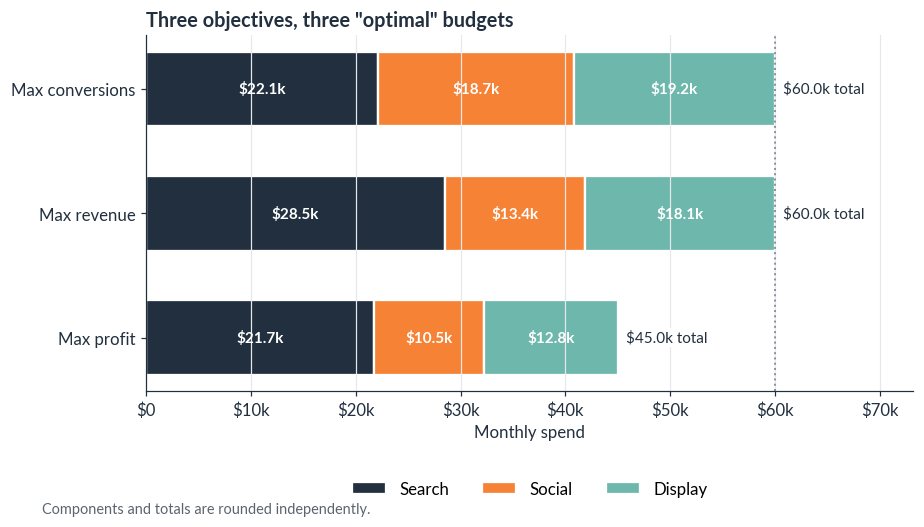

Saved tables/table02_objective_outcomes.png and a CSV copy


,Plan,Total spend,Conversions,Revenue,Profit,CPA,ROAS
0,Max conversions,"$60,000","2,430","$254,637","$54,587",$24.69,4.24
1,Max revenue,"$60,000","2,383","$259,503","$56,777",$25.17,4.33
2,Max profit,"$45,025","2,156","$233,111","$59,875",$20.89,5.18


In [6]:
def budget_bars(df, title, fname, height=4.2):
    fig, ax = plt.subplots(figsize=(9, height))
    names = df["Plan"].tolist()
    y = np.arange(len(names))[::-1]
    left = np.zeros(len(names))
    for c, col in zip(CH, [NAVY, ORANGE, TEAL]):
        vals = df[f"{c} spend"].values
        ax.barh(y, vals, left=left, color=col, height=0.6, label=c, edgecolor="white", linewidth=1.5)
        for yi, l, v in zip(y, left, vals):
            if v > 4500:
                ax.text(l + v / 2, yi, f"${v/1000:,.1f}k", ha="center", va="center", color="white",
                        fontsize=10, fontweight="bold")
        left += vals
    for yi, tot in zip(y, left):
        ax.text(tot + 800, yi, f"${tot/1000:,.1f}k total", va="center", fontsize=10, color=NAVY,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5), zorder=5)
    ax.axvline(BUDGET, color=GRAY, ls=":", lw=1.3)
    ax.set_yticks(y); ax.set_yticklabels(names)
    ax.set_xlim(0, BUDGET * 1.22)
    ax.xaxis.set_major_formatter(dollars_k)
    ax.set_xlabel("Monthly spend")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.34 if height < 4.6 else -0.28), ncol=3)
    fig.text(0.02, -0.13, "Components and totals are rounded independently.", ha="left", va="top",
             fontsize=9.5, color="#5b6570")
    save(fig, fname)
    plt.show()


def fmt_plans(df):
    return pd.DataFrame({
        "Plan": df["Plan"],
        "Total spend": df["Spend"].map(lambda v: f"${v:,.0f}"),
        "Conversions": df["Conversions"].map(lambda v: f"{v:,.0f}"),
        "Revenue": df["Revenue"].map(lambda v: f"${v:,.0f}"),
        "Profit": df["Profit"].map(lambda v: f"${v:,.0f}"),
        "CPA": df["CPA"].map(lambda v: f"${v:,.2f}"),
        "ROAS": df["ROAS"].map(lambda v: f"{v:.2f}"),
    })


budget_bars(p1, "Three objectives, three \"optimal\" budgets", "fig03_budget_by_objective.png")

t2 = fmt_plans(p1)
render_table("table02_objective_outcomes.png", "Same channels, different objectives",
             "What each objective's \"optimal\" budget delivers", t2, [17, 10, 11, 10, 10, 8, 6])
t2

Each objective found a real optimum. They just found different ones.

**Max conversions** puts more into Social than either of the other plans, because that's where conversions are cheapest. **Max revenue** shifts money toward Search, where each conversion is worth more. Both spend the full budget, because every extra dollar still buys a little more of what they're counting.

**Max profit** is the only objective that asks whether the last dollar earns its keep. It stops at about \$45,000 and leaves roughly $15,000 unspent. It delivers fewer conversions and less revenue than the other two plans, and more profit than either.

None of these plans is wrong. Each one is the right answer to a different question.

## 4. Part 2: Constraints change the answer

In practice, nobody optimizes with a blank slate. There are targets, commitments, and rules. In optimization terms, these are **constraints**: conditions the answer has to satisfy no matter what the objective says.

Constraints are useful. They encode things the objective doesn't capture, like a CPA target a client agreed to or a contract that commits spend to a channel. But they aren't free. To measure what each one costs, we'll keep the objective the same, **maximize profit**, and add one rule at a time:

1. **Target CPA:** CPA at or below \$20.
2. **Target ROAS:** ROAS at or above 5.5.
3. **Channel commitment:** at least \$25,000 on Display because of a contract.

All three rules matter here. The max-profit plan from Part 1 has a CPA of about \$20.89, a ROAS of about 5.18, and only about \$12,800 on Display, so each rule forces a change.

In [7]:
R = {
    "target_cpa": 20,
    "target_roas": 5.5,
    "display_minimum": 25000,
}

def cpa_rule(target):
    # CPA <= target, written without division as: target x conversions - spend >= 0.
    # This holds at any spend level, and zero spend satisfies it (nothing spent, nothing over target).
    return lambda s: (target * conversions(s).sum() - np.sum(s)) / BUDGET

def roas_rule(target):
    # ROAS >= target, written without division as: revenue - target x spend >= 0.
    # Zero spend satisfies it too, so both rules treat a zero budget the same way.
    return lambda s: ((conversions(s) * VAL).sum() - target * np.sum(s)) / BUDGET

def display_bounds(minimum):
    return [(0, BUDGET), (0, BUDGET), (minimum, BUDGET)]

plans2 = {
    "Max profit (no extra rules)": plans1["Max profit"],
    f"Max profit with CPA of ${R['target_cpa']} or less": optimize(obj_profit, [cpa_rule(R["target_cpa"])]),
    f"Max profit with ROAS of {R['target_roas']} or more": optimize(obj_profit, [roas_rule(R["target_roas"])]),
    f"Max profit with Display at ${R['display_minimum']/1000:,.0f}k or more":
        optimize(obj_profit, bounds=display_bounds(R["display_minimum"])),
}
p2 = plan_table(plans2)
best_profit = p2["Profit"].iloc[0]
p2["Opportunity cost"] = best_profit - p2["Profit"]
p2.round(2)

,Plan,Search spend,Social spend,Display spend,Spend,Conversions,Revenue,Profit,CPA,ROAS,Opportunity cost
0,Max profit (no extra rules),21740.14,10521.23,12763.36,45024.74,2155.72,233111.10,59875.26,20.89,5.18,0.00
1,Max profit with CPA of $20 or less,20111.78,10358.67,11753.78,42224.24,2111.21,226557.81,59726.78,20.00,5.37,148.48
2,Max profit with ROAS of 5.5 or more,19624.89,9614.69,11101.38,40340.96,2058.80,221875.26,59502.91,19.59,5.50,372.35
3,Max profit with Display at $25k or more,21740.14,10521.23,25000.00,57261.37,2292.46,249519.15,55022.24,24.98,4.36,4853.02


Saved figures/fig04_budget_by_constraint.png


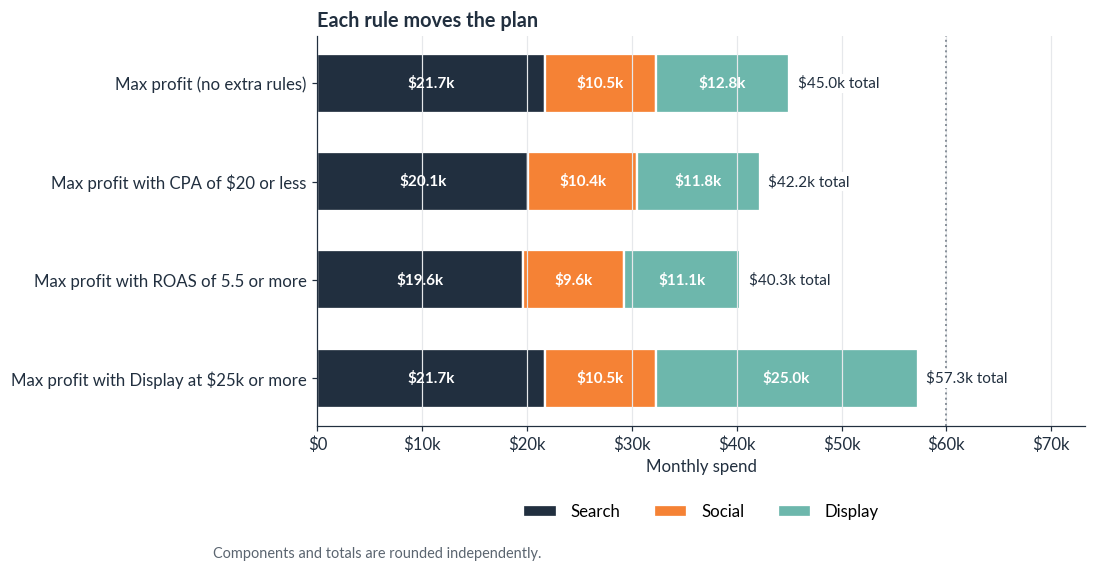

Saved figures/fig05_cost_of_constraints.png


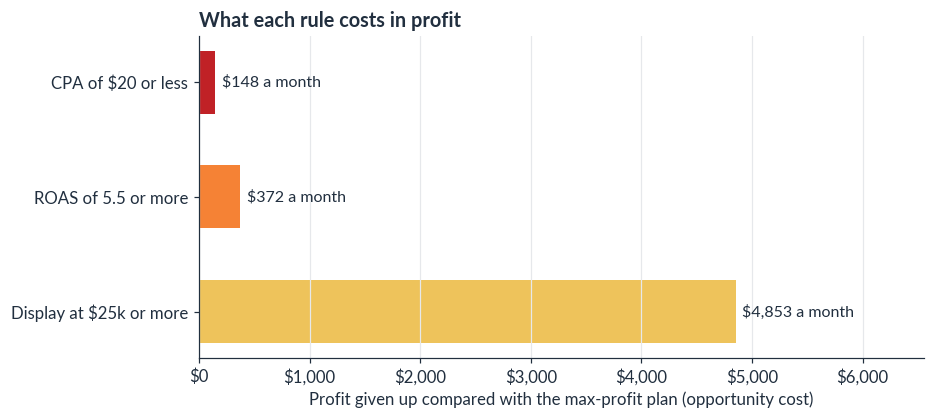

Saved tables/table03_constraint_costs.png and a CSV copy


,Plan,Total spend,Conversions,Profit,CPA,ROAS,Opportunity cost
0,No extra rules,"$45,025","2,156","$59,875",$20.89,5.18,$0
1,CPA of $20 or less,"$42,224","2,111","$59,727",$20.00,5.37,$148
2,ROAS of 5.5 or more,"$40,341","2,059","$59,503",$19.59,5.50,$372
3,Display at $25k or more,"$57,261","2,292","$55,022",$24.98,4.36,"$4,853"


In [8]:
budget_bars(p2, "Each rule moves the plan", "fig04_budget_by_constraint.png", height=4.6)

short = {p2["Plan"][1]: f"CPA of ${R['target_cpa']} or less",
         p2["Plan"][2]: f"ROAS of {R['target_roas']} or more",
         p2["Plan"][3]: f"Display at ${R['display_minimum']/1000:,.0f}k or more"}
fig, ax = plt.subplots(figsize=(8.5, 3.8))
names = [short[n] for n in p2["Plan"].tolist()[1:]]
gives = p2["Opportunity cost"].values[1:]
y = np.arange(len(names))[::-1]
ax.barh(y, gives, color=[RED, ORANGE, GOLD], height=0.55)
for yi, g in zip(y, gives):
    ax.text(g + 60, yi, f"${g:,.0f} a month", va="center", fontsize=10.5, color=NAVY)
ax.set_yticks(y); ax.set_yticklabels(names)
ax.xaxis.set_major_formatter(dollars)
ax.set_xlim(0, gives.max() * 1.35)
ax.set_xlabel("Profit given up compared with the max-profit plan (opportunity cost)")
ax.set_title("What each rule costs in profit")
ax.grid(axis="y", visible=False)
save(fig, "fig05_cost_of_constraints.png")
plt.show()

t3 = fmt_plans(p2)
t3["Plan"] = ["No extra rules"] + names
t3["Opportunity cost"] = p2["Opportunity cost"].map(lambda v: f"${v:,.0f}")
t3 = t3.drop(columns=["Revenue"])
render_table("table03_constraint_costs.png", "Constraints change the answer",
             "Maximizing profit under each rule, and what the rule costs", t3, [19, 10, 11, 10, 8, 6, 11])
t3

The costs aren't what most people would guess.

The **CPA target** barely matters. The max-profit plan was already close to $20, so trimming spend slightly to hit the target costs very little. The **ROAS target** costs more, because reaching 5.5 means pulling back further from channels that are still profitable at the margin. The **Display commitment** costs the most by far. The optimizer still maximizes profit, but it has to put money where the next dollar brings back less than a dollar in contribution.

Each of these numbers is the rule's **opportunity cost**: how much less profit the best plan earns with the rule than without it. A rule only costs something if it **binds**, meaning it forces the plan to change. A CPA target of $25 would cost nothing here, because the max-profit plan already beats it. That's different from a **shadow price**, which asks a marginal question: what would one more unit of the rule cost? The next cell calculates both kinds of marginal cost.

In [9]:
def max_profit_value(**kw):
    return outcomes(optimize(obj_profit, **kw))["Profit"]

shadow_plans = {}
def profit_at(name, **kw):
    s = optimize(obj_profit, **kw)
    shadow_plans[name] = (s, kw)
    return outcomes(s)["Profit"]

dmin = R["display_minimum"]
d_now = profit_at("Display at minimum", bounds=display_bounds(dmin))
d_tiny = profit_at("Display minimum + $10", bounds=display_bounds(dmin + 10))
d_big = profit_at("Display minimum + $1,000", bounds=display_bounds(dmin + 1000))
display_shadow = (d_now - d_tiny) / 10          # marginal cost at the current minimum
display_avg_1k = (d_now - d_big) / 1000          # average cost over the next $1,000

c_now = profit_at("CPA at target", rules=[cpa_rule(R["target_cpa"])])
c_tight = profit_at("CPA at target - $1", rules=[cpa_rule(R["target_cpa"] - 1)])

shadow = pd.DataFrame([
    [f"Display minimum at ${dmin:,}: one more required dollar",
     f"About ${display_shadow:.2f} less profit", "The shadow price of the Display rule"],
    [f"Display minimum rises from ${dmin:,} to ${dmin + 1000:,}",
     f"${d_now - d_big:,.0f} less profit", f"An average of ${display_avg_1k:.2f} per dollar over that range"],
    [f"CPA target tightens from ${R['target_cpa']} to ${R['target_cpa'] - 1}",
     f"${c_now - c_tight:,.0f} less profit", "Much more than the first step cost"],
], columns=["Change to the rule", "Effect on monthly profit", "What it means"])
shadow

,Change to the rule,Effect on monthly profit,What it means
0,"Display minimum at $25,000: one more required ...",About $0.67 less profit,The shadow price of the Display rule
1,"Display minimum rises from $25,000 to $26,000",$686 less profit,An average of $0.69 per dollar over that range
2,CPA target tightens from $20 to $19,$554 less profit,Much more than the first step cost


At a \$25K minimum, each additional required dollar on Display costs about 67 cents in profit. That's the **shadow price** of the Display rule, a marginal number. Over a bigger step, from \$25K to \$26K, the cost averages about 69 cents per dollar, because each extra dollar of Display earns a little less than the one before. Either number is useful to bring to a contract negotiation.

The CPA example shows why shadow prices change as a rule tightens. Moving the target from about \$20.89 to \$20 cost very little. Moving it from \$20 to \$19 costs several times more. Each step pushes the plan further from where the business would choose to be.

A constraint is a business decision in its own right. It's worth asking, for each one, what it protects and what it costs.

## 5. Part 3: Blending goals into a utility function

Most businesses don't care about only one number. A growing company might want conversions to build its customer base and profit to stay healthy. When you care about two things, you have to say how much you care about each. That's a **utility function**.

The simplest version is a weighted blend:

**utility = w × (profit ÷ best possible profit) + (1 − w) × (conversions ÷ most possible conversions)**

Profit and conversions are measured in different units, so each one is first scaled to a share of its best possible value. That makes a weight of 0.5 mean equal weight on each outcome *as a share of its maximum*. It does **not** mean one conversion is worth one dollar of profit. The scaling is a modeling choice, and a different scale could produce a different plan for the same weight.

We'll sweep the weight from 0 (only conversions matter) to 1 (only profit matters) and solve the budget problem at each step.

Saved figures/fig06_utility_frontier.png


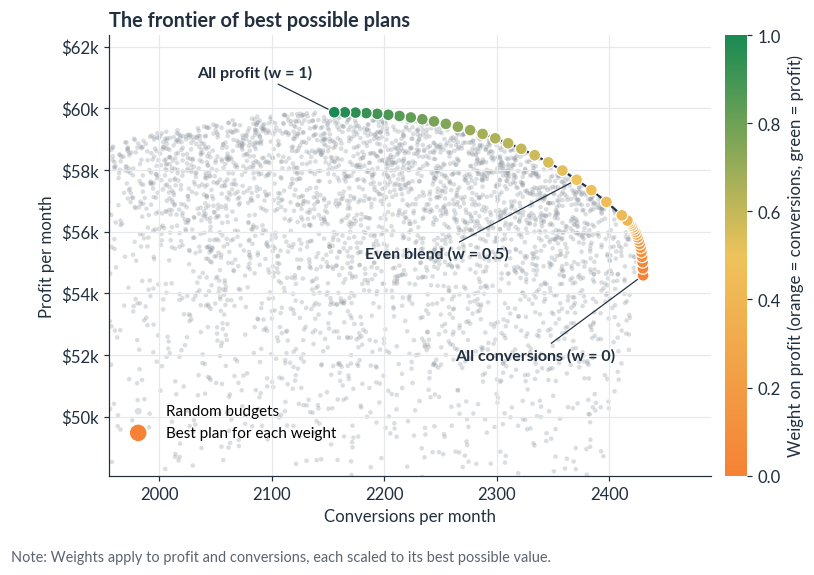

Random budgets that beat a frontier plan on both conversions and profit: 0 of 4,000


In [10]:
from matplotlib.colors import LinearSegmentedColormap

U = {
    "weights": np.round(np.linspace(0, 1, 41), 3),
    "random_plans": 4000,   # random budgets to compare against the frontier
}

best_conv = outcomes(plans1["Max conversions"])["Conversions"]
best_prof = outcomes(plans1["Max profit"])["Profit"]

def utility_objective(w):
    def f(s):
        share_conv = conversions(s).sum() / best_conv
        share_prof = -obj_profit(s) / best_prof
        return -(w * share_prof + (1 - w) * share_conv)
    return f

frontier = []
for w in U["weights"]:
    s = optimize(utility_objective(w))
    frontier.append({"Profit weight": w, **{f"{c} spend": v for c, v in zip(CH, s)}, **outcomes(s)})
frontier = pd.DataFrame(frontier)

# Random budgets, mostly in a sensible range, for comparison
k = U["random_plans"]
shares = rng.dirichlet([8, 5, 6], k)
totals = rng.uniform(35000, BUDGET, k)
rand = pd.DataFrame([outcomes(sh * t) for sh, t in zip(shares, totals)])

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.scatter(rand["Conversions"], rand["Profit"], s=9, color=GRAY, alpha=0.3, edgecolor="none",
           label="Random budgets")
sc = ax.scatter(frontier["Conversions"], frontier["Profit"], c=frontier["Profit weight"],
                cmap=LinearSegmentedColormap.from_list("w", [ORANGE, GOLD, GREEN]),
                s=60, edgecolor="white", linewidth=0.8, zorder=4, label="Best plan for each weight")
ax.plot(frontier["Conversions"], frontier["Profit"], color=NAVY, lw=1.4, zorder=3)
for w, dx, dy in [(0.0, -25, -2600), (0.5, -60, -2400), (1.0, -20, 1300)]:
    r = frontier.loc[frontier["Profit weight"] == w].iloc[0]
    label = {0.0: "All conversions (w = 0)", 0.5: "Even blend (w = 0.5)", 1.0: "All profit (w = 1)"}[w]
    ax.annotate(label, xy=(r["Conversions"], r["Profit"]), xytext=(r["Conversions"] + dx, r["Profit"] + dy),
                ha="right", va="center", fontsize=10.5, color=NAVY, fontweight="bold",
                arrowprops=dict(arrowstyle="-", color=NAVY, lw=0.8))
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label("Weight on profit (orange = conversions, green = profit)")
cb.outline.set_visible(False)
ax.yaxis.set_major_formatter(dollars_k)
ax.set_xlabel("Conversions per month")
ax.set_ylabel("Profit per month")
ax.set_xlim(frontier["Conversions"].min() - 200, best_conv + 60)
ax.set_ylim(frontier["Profit"].min() - 6500, best_prof + 2500)
fig.text(0.02, -0.02, "Note: Weights apply to profit and conversions, each scaled to its best possible value.",
         ha="left", va="top", fontsize=9.5, color="#5b6570")
ax.set_title("The frontier of best possible plans")
ax.legend(loc="lower left", fontsize=10, markerscale=1.5, bbox_to_anchor=(0, 0.05))
save(fig, "fig06_utility_frontier.png")
plt.show()

# Dominance check: does any random plan beat a frontier plan on both measures?
fc, fp = frontier["Conversions"].values, frontier["Profit"].values
rc, rp = rand["Conversions"].values[:, None], rand["Profit"].values[:, None]
dominates = (rc >= fc) & (rp >= fp) & ((rc > fc + 0.01) | (rp > fp + 0.01))
print(f"Random budgets that beat a frontier plan on both conversions and profit: {int(dominates.any(axis=1).sum())} of {k:,}")

In [11]:
pick = frontier[frontier["Profit weight"].isin([0.0, 0.25, 0.5, 0.75, 1.0])]
t4 = pd.DataFrame({
    "Weight on profit": pick["Profit weight"].map(lambda v: f"{v:.0%}"),
    "Search": pick["Search spend"].map(lambda v: f"${v:,.0f}"),
    "Social": pick["Social spend"].map(lambda v: f"${v:,.0f}"),
    "Display": pick["Display spend"].map(lambda v: f"${v:,.0f}"),
    "Total spend": pick["Spend"].map(lambda v: f"${v:,.0f}"),
    "Conversions": pick["Conversions"].map(lambda v: f"{v:,.0f}"),
    "Profit": pick["Profit"].map(lambda v: f"${v:,.0f}"),
})
render_table("table04_utility_weights.png", "Blending goals into a utility function",
             "The best plan depends on how much you value each outcome", t4, [12, 9, 9, 9, 10, 11, 9])
t4

Saved tables/table04_utility_weights.png and a CSV copy


,Weight on profit,Search,Social,Display,Total spend,Conversions,Profit
0,0%,"$22,093","$18,711","$19,196","$60,000","2,430","$54,587"
10,25%,"$24,908","$16,709","$18,383","$60,000","2,423","$55,996"
20,50%,"$24,984","$14,667","$16,898","$56,548","2,371","$57,687"
30,75%,"$22,907","$12,241","$14,321","$49,468","2,255","$59,498"
40,100%,"$21,740","$10,521","$12,763","$45,025","2,156","$59,875"


Each point on the line is the best possible plan for one weighting of profit and conversions. The colors show the weight: orange points put more emphasis on conversions, and green points put more emphasis on profit. None of them is "the" optimum.

Economists call this line the **Pareto frontier**. Along it, you can't get more conversions without giving up some profit, or more profit without giving up some conversions. The gray cloud shows 4,000 random budgets, and the check above confirms that none of them beats a frontier plan on both measures. Those plans are simply worse.

Two notes on what this shows. The 41 points are a sample of the frontier, not every possible optimal plan. And a weighted blend works well here because the response curves are smooth and bend in one direction. In messier problems, a weighted sum can miss parts of the frontier, so other methods are used.

That leads to a useful way to think about any marketing plan:

- **If a plan sits below the frontier,** it's leaving money or customers on the table, and better analysis can fix that.
- **Once a plan is on the frontier,** better analysis can't pick the point for you. Choosing between more growth and more profit is a judgment about what the business values.

The same idea shows up in Robyn, Meta's open-source media mix modeling package, at a different stage. Its [Analyst's Guide to MMM](https://facebookexperimental.github.io/Robyn/docs/analysts-guide-to-MMM) describes the process. Robyn uses a Pareto frontier to **choose among models**, balancing statistical fit against how plausible each model's results are. Once a model is chosen, its budget allocator can then **choose among budgets**, which is the kind of decision this notebook makes. Same principle, two different decisions.

## 6. Part 4: Which objective fits your business?

The math can find the best plan for any objective. It can't tell you which objective to use. That depends on what the business is trying to accomplish right now.

The table below matches common business situations to the objective that fits them, with what that objective delivered in this simulation and what to watch for. These aren't universal rules. They're a starting point for the conversation.

In [12]:
o_conv = outcomes(plans1["Max conversions"])
o_rev = outcomes(plans1["Max revenue"])
o_prof = outcomes(plans1["Max profit"])
cost = p2["Opportunity cost"].values
mid = frontier.loc[frontier["Profit weight"] == 0.5].iloc[0]

biz = pd.DataFrame({
    "Business situation": [
        "Building a customer base quickly",
        "Growing top-line sales",
        "Protecting profitability",
        "Balancing growth and profitability",
        "Honoring a contract or brand commitment",
        "Meeting a client's KPI target",
    ],
    "Objective that fits": [
        "Maximize conversions",
        "Maximize revenue",
        "Maximize contribution profit",
        "Weighted utility of profit and conversions",
        "Maximize profit with a spending constraint",
        "Maximize profit with a CPA or ROAS constraint",
    ],
    "In this simulation": [
        f"{o_conv['Conversions']:,.0f} conversions, ${o_conv['Profit']:,.0f} profit",
        f"${o_rev['Revenue']:,.0f} revenue, ${o_rev['Profit']:,.0f} profit",
        f"${o_prof['Profit']:,.0f} profit, ${BUDGET - o_prof['Spend']:,.0f} left unspent",
        f"Even blend: {mid['Conversions']:,.0f} conversions, ${mid['Profit']:,.0f} profit",
        f"$25k on Display gives up ${cost[3]:,.0f} a month in profit",
        f"A ${R['target_cpa']} CPA target gives up ${cost[1]:,.0f} a month in profit",
    ],
    "Watch out for": [
        "Cheap conversions can be low-value customers",
        "Revenue can rise while margins shrink",
        "Underinvesting in long-term growth",
        "The weights are a judgment call",
        "Commitments that no longer pay for themselves",
        "Treating the target as the goal",
    ],
})
render_table("table05_which_objective_fits.png", "Which objective fits your business?",
             "The math finds the best plan. The business decides what \"best\" means.",
             biz, [24, 26, 30, 26])
biz

Saved tables/table05_which_objective_fits.png and a CSV copy


,Business situation,Objective that fits,In this simulation,Watch out for
0,Building a customer base quickly,Maximize conversions,"2,430 conversions, $54,587 profit",Cheap conversions can be low-value customers
1,Growing top-line sales,Maximize revenue,"$259,503 revenue, $56,777 profit",Revenue can rise while margins shrink
2,Protecting profitability,Maximize contribution profit,"$59,875 profit, $14,975 left unspent",Underinvesting in long-term growth
3,Balancing growth and profitability,Weighted utility of profit and conversions,"Even blend: 2,371 conversions, $57,687 profit",The weights are a judgment call
4,Honoring a contract or brand commitment,Maximize profit with a spending constraint,"$25k on Display gives up $4,853 a month in profit",Commitments that no longer pay for themselves
5,Meeting a client's KPI target,Maximize profit with a CPA or ROAS constraint,A $20 CPA target gives up $148 a month in profit,Treating the target as the goal


### Same objective, different assumptions

Choosing the right objective is only half the job. The answer also depends on the assumptions behind it. Here's the max-profit plan at three different gross margins, with everything else held constant.

In [13]:
rows, sens_plans = [], {}
for m in [0.35, 0.45, 0.60]:
    s = optimize(lambda x, m=m: obj_profit(x, margin=m))
    sens_plans[f"Max profit at {m:.0%} margin"] = s
    o = outcomes(s, margin=m)
    rows.append({"Gross margin": f"{m:.0%}", "Search": f"${s[0]:,.0f}", "Social": f"${s[1]:,.0f}",
                 "Display": f"${s[2]:,.0f}", "Total spend": f"${o['Spend']:,.0f}",
                 "Profit": f"${o['Profit']:,.0f}"})
sens = pd.DataFrame(rows)
render_table("table06_margin_sensitivity.png", "Same objective, different assumptions",
             "The max-profit budget at three gross margins", sens, [12, 10, 10, 10, 12, 10])
sens

Saved tables/table06_margin_sensitivity.png and a CSV copy


,Gross margin,Search,Social,Display,Total spend,Profit
0,35%,"$18,222","$9,013","$9,999","$37,234","$37,466"
1,45%,"$21,740","$10,521","$12,763","$45,025","$59,875"
2,60%,"$25,768","$12,247","$15,928","$53,943","$96,257"


A higher margin makes every conversion worth more, so the optimizer spends more before the next dollar stops paying for itself. The objective didn't change. The assumptions did, and so did the answer.

### Optimizing the right thing badly

There are two ways an optimization can go wrong, and they're easy to confuse:

1. **Choosing the wrong objective.** Maximizing conversions might favor a channel full of low-value customers. Maximizing revenue might ignore what it costs to get there. This is the cobra effect in another form: the optimizer delivers exactly what you asked for, not what you wanted.
2. **Measuring the right objective poorly.** Even profit optimization fails if the value per conversion, the margin, or the response curves are wrong. This optimizer treats every conversion in a channel as worth the same and trusts the curves completely. Real marketing data is rarely that clean.

Either mistake can produce an answer that's mathematically optimal and commercially disappointing. Good objective functions depend on good measurement.

## 7. A brief note on loss functions

Everything above is an objective a business chooses. Models have objectives too. When a model learns from data, it searches for the settings that make its errors as small as possible, and the formula that measures those errors is called a **loss function**. A loss function is an objective function for fitting data.

The choice matters here as well. Squared error, the most common loss, penalizes big misses heavily and leads a flexible model toward the **conditional mean**: the average outcome for customers with the same characteristics. Absolute error treats every dollar of miss the same and leads toward the **conditional median**. Both depend on the model being flexible enough to represent them. For a single summary number with no predictors, the result is exact: squared error picks the mean and absolute error picks the median. On data with a few very large customers, the two choices can produce very different models from the same numbers.

The two levels work together. **A predictive model minimizes a loss function to learn from data. A business optimization uses those predictions to choose an action according to a business objective.** The response curves in this notebook are the kind of thing a predictive model would supply, and the budget optimizer is the business decision built on top of them.

Loss functions deserve their own article, and I plan to cover them, along with gradient descent, in future pieces.

## 8. Checking the results

A check that every plan the notebook produced follows its own rules: the three Part 1 plans, the four Part 2 plans, every shadow-price plan, all 41 utility plans, and the three margin plans. If any plan fails, this cell stops with an error.

In [14]:
def check(name, s, cpa_max=None, roas_min=None, display_min=None):
    o = outcomes(s)
    ok = {"Within budget": o["Spend"] <= BUDGET + 1, "No negative spend": bool((np.asarray(s) >= -1e-6).all())}
    # Same division-free rules the optimizer uses, so zero spend is handled consistently
    if cpa_max is not None: ok["CPA target met"] = cpa_max * o["Conversions"] - o["Spend"] >= -1.0
    if roas_min is not None: ok["ROAS target met"] = o["Revenue"] - roas_min * o["Spend"] >= -1.0
    if display_min is not None: ok["Display minimum met"] = s[2] >= display_min - 1
    return {"Plan": name, "All rules met": all(ok.values()), "Checks": ", ".join(ok)}

names2 = list(plans2)
checks = [check(n, s) for n, s in plans1.items()]
checks += [check(names2[0], plans2[names2[0]]),
           check(names2[1], plans2[names2[1]], cpa_max=R["target_cpa"]),
           check(names2[2], plans2[names2[2]], roas_min=R["target_roas"]),
           check(names2[3], plans2[names2[3]], display_min=R["display_minimum"])]
for name, (s, kw) in shadow_plans.items():
    lo = kw.get("bounds", [(0, 0)] * 3)[2][0]
    cpa = R["target_cpa"] - (1 if "- $1" in name else 0) if "CPA" in name else None
    checks.append(check(f"Shadow price: {name}", s, cpa_max=cpa, display_min=lo if lo else None))
checks += [check(f"Utility, w = {w:.3f}", frontier.loc[i, [f"{c} spend" for c in CH]].values)
           for i, w in enumerate(frontier["Profit weight"])]
checks += [check(n, s) for n, s in sens_plans.items()]
checks = pd.DataFrame(checks)

ends_match = (np.isclose(frontier["Conversions"].iloc[0], o_conv["Conversions"], atol=0.5) and
              np.isclose(frontier["Profit"].iloc[-1], o_prof["Profit"], atol=1))
if not checks["All rules met"].all():
    raise AssertionError("Some plans broke a rule:\n" + checks.loc[~checks["All rules met"], "Plan"].to_string())
if not ends_match:
    raise AssertionError("The utility frontier's endpoints don't match the single-objective plans.")
print(f"All {len(checks)} plans follow their rules, and the frontier endpoints match the single-objective plans.")
checks

All 56 plans follow their rules, and the frontier endpoints match the single-objective plans.


,Plan,All rules met,Checks
0,Max conversions,True,"Within budget, No negative spend"
1,Max revenue,True,"Within budget, No negative spend"
2,Max profit,True,"Within budget, No negative spend"
3,Max profit (no extra rules),True,"Within budget, No negative spend"
4,Max profit with CPA of $20 or less,True,"Within budget, No negative spend, CPA target met"
5,Max profit with ROAS of 5.5 or more,True,"Within budget, No negative spend, ROAS target met"
6,Max profit with Display at $25k or more,True,"Within budget, No negative spend, Display mini..."
7,Shadow price: Display at minimum,True,"Within budget, No negative spend, Display mini..."
8,Shadow price: Display minimum + $10,True,"Within budget, No negative spend, Display mini..."
9,"Shadow price: Display minimum + $1,000",True,"Within budget, No negative spend, Display mini..."


SLSQP is a numerical method, not a mathematical proof that it found the single best answer. Here, the response curves are smooth and bend in one direction, and the notebook starts the search from several places, so there's good reason to trust the results. With a messier model, you'd want more checks.

## 9. Summary

In [15]:
summary = pd.DataFrame([
    ["Search alone: most profitable monthly spend", f"${grid[best_i]:,.0f}"],
    ["Part 1: Spend, max conversions / max revenue / max profit",
     f"${o_conv['Spend']:,.0f} / ${o_rev['Spend']:,.0f} / ${o_prof['Spend']:,.0f}"],
    ["Part 1: Profit, max conversions vs. max profit", f"${o_conv['Profit']:,.0f} vs. ${o_prof['Profit']:,.0f}"],
    ["Part 1: Conversions, max conversions vs. max profit", f"{o_conv['Conversions']:,.0f} vs. {o_prof['Conversions']:,.0f}"],
    ["Part 2: Opportunity cost of a $20 CPA target", f"${cost[1]:,.0f} a month"],
    ["Part 2: Opportunity cost of a 5.5 ROAS target", f"${cost[2]:,.0f} a month"],
    ["Part 2: Opportunity cost of $25k on Display", f"${cost[3]:,.0f} a month"],
    ["Part 2: Shadow price of the Display minimum at $25k", f"${display_shadow:.2f} per extra required dollar"],
    ["Part 3: Even blend (w = 0.5), conversions and profit", f"{mid['Conversions']:,.0f} and ${mid['Profit']:,.0f}"],
], columns=["Result", "Value"])
summary

,Result,Value
0,Search alone: most profitable monthly spend,"$21,700"
1,"Part 1: Spend, max conversions / max revenue /...","$60,000 / $60,000 / $45,025"
2,"Part 1: Profit, max conversions vs. max profit","$54,587 vs. $59,875"
3,"Part 1: Conversions, max conversions vs. max p...","2,430 vs. 2,156"
4,Part 2: Opportunity cost of a $20 CPA target,$148 a month
5,Part 2: Opportunity cost of a 5.5 ROAS target,$372 a month
6,Part 2: Opportunity cost of $25k on Display,"$4,853 a month"
7,Part 2: Shadow price of the Display minimum at...,$0.67 per extra required dollar
8,"Part 3: Even blend (w = 0.5), conversions and ...","2,371 and $57,687"


### Takeaways

1. **Every optimization has an objective.** It's the definition of "best," and it's often a default nobody chose on purpose.
2. **The same channels can have several right answers.** Maximizing conversions, revenue, and profit each produce a sensible plan, and each answers a different question.
3. **Profit is the objective that asks whether the next dollar pays for itself.** Volume objectives keep spending as long as the next dollar buys anything at all.
4. **Constraints are decisions, and they have a price.** Some cost almost nothing. Others cost a lot. It's worth knowing which is which.
5. **When you value more than one thing, the weights are the decision.** Analysis can get you onto the frontier. Choosing a point on it is a business judgment.
6. **Good objectives need good measurement.** The wrong objective and a poorly measured right one can both produce answers that are optimal on paper and disappointing in practice.

An optimizer can tell you which marketing budget is best for a particular objective. It can't tell you which objective your business should care about most.

### Try it yourself

The numbers in the text describe the default settings. Change a setting and rerun everything to see new results in the code, charts, and tables.

- In the `P` cell, raise `gross_margin` to 0.6 and rerun. How does every part of the notebook change?
- In the `R` cell, change `display_minimum` to $15,000. How much of the cost disappears?
- In Part 3, look at the frontier table. Which weight matches how your business actually makes decisions?

### Related articles

- [The Cobra Effect: When Marketing Metrics Bite Back](https://blog.marketingdatascience.ai/the-cobra-effect-when-marketing-metrics-bite-back-d4ac686c1b8d)
- [Marketing Mix Modeling with Robyn: How to Build Your First MMM Step-by-Step](https://blog.marketingdatascience.ai/marketing-mix-modeling-with-robyn-how-to-build-your-first-mmm-step-by-step-6ddf95d01094)
- [Is It Worth It? How to Run a Cost-Benefit Analysis for Better Marketing Decisions](https://blog.marketingdatascience.ai/is-it-worth-it-how-to-run-a-cost-benefit-analysis-for-better-marketing-decisions-5a8dd38216e2)
- [A Marketer's Guide to Calculus](https://blog.marketingdatascience.ai/a-marketers-guide-to-calculus-9ced95758447)
- [Weighted Average Cost of Marketing (WACM): A Risk-Adjusted Hurdle Rate for Smarter Marketing Investments](https://blog.marketingdatascience.ai/weighted-average-cost-of-marketing-wacm-a-risk-adjusted-hurdle-rate-for-smarter-marketing-948b05e45186)

---

*Joe Domaleski is the founder of Country Fried Creative, a digital marketing agency in Peachtree City, Georgia. He holds an MBA from Georgia State University and an MS in Analytics from Georgia Tech.*